# AireMañana — tomorrow's NO₂ alert for a Madrid school

**Track:** AI + Climate · **Place:** Madrid, Spain — all 24 official stations (the model is built on *Escuelas Aguirre*, next to Retiro Park)
· **Website:** https://julianjms-beep.github.io/aire-manana/ · **Code:** https://github.com/julianjms-beep/aire-manana

**User.** A PE teacher at a school in Madrid. Every afternoon at 18:00 they decide whether tomorrow's PE class and recess
happen outdoors. Children with asthma are the most affected by nitrogen dioxide (NO₂), the gas that comes mostly from traffic.

**What goes in → what comes out.** At 18:00: today's NO₂ measured by Madrid's official network (00:00–18:00), the last days,
the calendar and the ECMWF weather forecast for tomorrow → tomorrow's 24-hour mean NO₂ and an **alert** if it will go above
**50 µg/m³**, the EU daily limit value that applies from 2030 (Directive 2024/2881, at most 18 days a year).

**What makes it ours.**
1. **Our own data and place:** 2.4 million official hourly NO₂ values from Madrid's network (24 stations, 2015–2026), not a tutorial dataset.
2. **A realistic test:** the final test uses the weather forecast that ECMWF actually published *the day before* (archived by Open-Meteo), not the weather that happened.
3. **Our own question:** Madrid's NO₂ halved between 2015 and 2025 (low-emission zones, cleaner cars). *Does a model trained on the old, dirtier Madrid still work today — and how do we fix it?*

### How to read this notebook
Every result is followed by a short **"What this shows"** note in plain words, so the notebook can be read top to bottom
without running anything. To run it yourself, open it in Colab (link in the README) and choose *Runtime → Run all*; the first
run downloads the official data, which takes a few minutes.

| Section | Question it answers |
|---|---|
| 1. Data | What is measured, and how much has Madrid changed? |
| 2. Table and split | What does the model know at 18:00, and how is the test kept honest? |
| 3. Model choice | Which model and which alert threshold — chosen on validation only? |
| 4. Final test | How good is it on 932 days it never saw, with real day-before weather forecasts? |
| 5. Drift | Does a model trained on the old Madrid still work? How we fixed it |
| 6. Failures | Which bad days it misses, and how it does at all 24 stations |
| 7. Demo | Tomorrow's real forecast |
| 8. Schools | From 24 stations to 1,253 schools |
| 9. Best hour | When during the school day is the air cleanest? |
| 10. Website and live record | What is published every evening, and how it is checked |
| 11. Limitations | What it can't do yet |

### Words used in this notebook
* **NO₂ (nitrogen dioxide):** a gas that comes mostly from car exhaust; it irritates the airways.
* **µg/m³:** micrograms of gas in one cubic metre of air. The EU daily limit from 2030 is 50.
* **Daily mean:** the average of the 24 hourly values of a day. A **bad day** is a day above 50.
* **Persistence ("tomorrow = today"):** the simplest forecast — tomorrow will be like today so far. Every model must beat it.
* **Error (MAE, mean absolute error):** the average size of the miss in µg/m³, ignoring its sign. Lower is better.
* **Bias:** the average of (forecast − measured). Positive means the model expects dirtier air than there really is.
* **Recall / precision:** of the bad days, the share the alert caught / of the alerts, the share that were right.
* **Train / validation / test:** the years used to fit the model / to choose its settings / to score it once at the end.
* **ERA5 / ECMWF IFS:** the weather that really happened (reanalysis) / the weather forecast published the evening before.
* **Ridge regression / gradient-boosted trees:** a linear model / a model made of many small decision trees. AireMañana averages both.
* **Likely range and chance above 50:** the model's own past errors are added to tomorrow's forecast; the middle 80 % of
  the results is the likely range, and the share above 50 µg/m³ is the chance of a bad day.
* **30-day self-correction (v2):** every evening the model removes its own average error of the last 30 days it can check.

> This project is a prototype and is not medical advice.

## 0. Setup
Runs on Google Colab or locally. On Colab it downloads the project code from GitHub.

In [1]:
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.exists("forecast_model.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/julianjms-beep/aire-manana.git"], check=True)
    os.chdir("aire-manana")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "holidays", "pyarrow"], check=True)

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from madrid_data import (STATIONS, daily, download_history, read_history,
                         weather_observed, weather_forecast_day_before)
from forecast_model import (LIMIT, AireManana, LinearModel, TreeModel, build_table, scores,
                            baseline_persistence, baseline_yesterday, baseline_weekday_rule)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
STATION = 8  # Escuelas Aguirre

## 1. Data
* **Air quality:** Madrid City Council open data, validated hourly values for 24 stations, Jan 2015 – Oct 2026. Only hours flagged
  valid (`V`) are used; a day counts only with ≥ 18 valid hours. The decision is made at 18:00, so for *today* we only use 00:00–18:00.
* **Weather:** Open-Meteo. For training: ERA5 reanalysis (the weather that happened). For the test: the ECMWF IFS forecast issued
  the day before (Open-Meteo "previous runs" archive, available from March 2024).

The processed daily table is saved in `data/no2_daily.csv`; delete it to rebuild everything from the original files (~85 MB download).

In [2]:
if not os.path.exists("data/no2_daily.csv"):
    download_history()
    daily(read_history()).to_csv("data/no2_daily.csv", index=False)
no2 = pd.read_csv("data/no2_daily.csv", parse_dates=["date"])
weather_obs = weather_observed("2014-12-01", "2026-11-13")
weather_fc = weather_forecast_day_before("2024-03-01", "2026-11-15")
print(f"NO2 daily rows: {len(no2):,} · stations: {no2.station.nunique()} · {no2.date.min():%b %Y} – {no2.date.max():%b %Y}")
print(f"Weather days observed: {len(weather_obs):,} · archived day-ahead forecasts: {len(weather_fc):,}")
no2[no2.station == STATION].tail(3)

NO2 daily rows: 102,366 · stations: 24 · Jan 2015 – Oct 2026
Weather days observed: 4,366 · archived day-ahead forecasts: 990


,station,date,mean,max,hours,mean_to_18h,hours_to_18h
8377,8,2026-10-29,44.000000,107.0,24,34.611111,18.0
8378,8,2026-10-30,58.958333,129.0,24,44.944444,18.0
8379,8,2026-10-31,40.750000,133.0,24,21.333333,18.0


**What this shows.** 102,366 station-days: 24 stations × almost 12 years. Each row is one station and one day: the daily
mean, the highest hour, how many hours were valid, and the mean *up to 18:00* — the only part of today a teacher can know when
deciding. The weather tables hold 4,366 days of observed weather and 990 archived evening-before forecasts. Those forecasts are
only archived from March 2024, which is why the final test starts then.

### Madrid changed a lot
The yearly mean NO₂ at Escuelas Aguirre and the number of days above the 2030 daily limit:

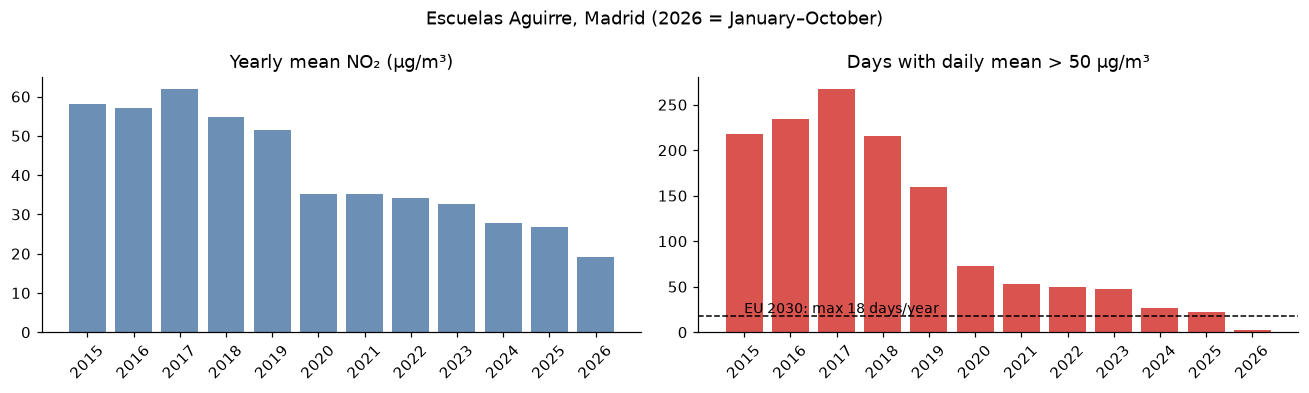

,mean_no2,days,days_above_50
year,,,
2015,58.1,358,218
2016,57.1,366,234
2017,61.9,363,267
2018,54.8,365,216
2019,51.5,349,160
2020,35.2,364,73
2021,35.3,359,53
2022,34.3,365,50
2023,32.6,364,48


In [3]:
s = no2[no2.station == STATION].dropna(subset=["mean"]).copy(); s["year"] = s.date.dt.year
yearly = s.groupby("year").agg(mean_no2=("mean", "mean"), days=("mean", "size"),
                               days_above_50=("mean", lambda x: int((x > LIMIT).sum())))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(yearly.index, yearly.mean_no2, color="#6b8fb5"); ax[0].set_title("Yearly mean NO₂ (µg/m³)")
ax[1].bar(yearly.index, yearly.days_above_50, color="#d9534f"); ax[1].axhline(18, color="k", ls="--", lw=1)
ax[1].text(2015, 21, "EU 2030: max 18 days/year", fontsize=9); ax[1].set_title("Days with daily mean > 50 µg/m³")
for a in ax: a.set_xticks(yearly.index); a.tick_params(axis="x", rotation=45)
fig.suptitle("Escuelas Aguirre, Madrid (2026 = January–October)"); fig.tight_layout(); fig.savefig("figures/decline.png", dpi=150); plt.show()
yearly.round(1)

**What this shows.** In 2017 Escuelas Aguirre broke the 2030 daily limit on 267 days; in 2025 on 22, and in 2026 (up to the end
of October, before the dirtiest months) on only 2. The yearly mean fell from about 60 to 27 µg/m³ in 2025. The dashed line is the
EU 2030 rule: at most 18 days a year. Great news for children — but a trap for a model, because the past it learns from is
dirtier than the present it has to forecast. Section 5 shows what that does.

## 2. The forecasting table and a fair split by time
One row per day *D*: everything known at 18:00 and the target (*mean NO₂ of D+1*). Days are **never shuffled**:

| Set | Period | Weather for tomorrow | Used for |
|---|---|---|---|
| Train | Jul 2020 – Dec 2022 | what happened (ERA5) | fitting |
| Validation | Jan 2023 – Feb 2024 | what happened (ERA5) | choosing the model, training years and alert threshold |
| **Test** | **Mar 2024 – Oct 2026** | **ECMWF forecast from the day before** | **final score, used once** |

For the final test, the chosen model is re-trained on train + validation.

In [4]:
T_obs = build_table(no2, STATION, weather_obs, weather_obs).dropna(subset=["target", "no2_today_to_18h"])
T_fc = build_table(no2, STATION, weather_obs, weather_fc).dropna(subset=["target", "no2_today_to_18h", "temp_mean_tomorrow"])
period = lambda T, a, b: T[(T.date >= a) & (T.date <= b)]
val = period(T_obs, "2023-01-01", "2024-02-28")
test = T_fc[T_fc.date >= "2024-02-29"]
print(f"validation days: {len(val)} · test days: {len(test)} ({test.date.min():%d %b %Y} – {test.date.max():%d %b %Y})")
print(f"bad days (> {LIMIT:.0f} µg/m³) — validation: {(val.target > LIMIT).sum()}, test: {(test.target > LIMIT).sum()}")

validation days: 417 · test days: 932 (29 Feb 2024 – 30 Oct 2026)
bad days (> 50 µg/m³) — validation: 54, test: 45


**What this shows.** 417 validation days and 932 test days. Only 45 of the 932 test days were bad days (about 5 %), so the
alert results rest on few events.

## 3. Choosing the model on validation data only
* **Baselines:** *persistence* ("tomorrow = today so far", required by the track), *yesterday*, and a *weekday rule*
  (today × the usual change for that pair of weekdays — e.g. Saturday→Sunday drops). The weekday rule shows how much of the
  model's gain comes from the calendar alone.
* **Models:** a linear (ridge) regression and gradient-boosted trees. Both predict the **change** from today to tomorrow on a
  log scale (*relative*); we also try predicting the **absolute** level, and three training windows.

In [5]:
rows = []
def add(name, window, T, pred):
    rows.append({"method": name, "train_from": window, **scores(T.target, pred)})

train0 = period(T_obs, "2015-01-08", "2022-12-31")
add("Baseline: persistence (today so far)", "-", val, baseline_persistence(val))
add("Baseline: yesterday", "-", val, baseline_yesterday(val))
add("Baseline: weekday rule", "2015", val, baseline_weekday_rule(train0, val))
for start in ["2015-01-08", "2018-01-01", "2020-07-01"]:
    tr = period(T_obs, start, "2022-12-31")
    for name, model in [("Linear, absolute", LinearModel(relative=False)), ("Linear, relative", LinearModel()),
                        ("Trees, absolute", TreeModel(relative=False)), ("Trees, relative", TreeModel()),
                        ("Blend linear+trees, relative", AireManana())]:
        add(name, start[:4], val, model.fit(tr).predict(val))
train = period(T_obs, "2020-07-01", "2022-12-31")
add("Blend + 30-day error correction (v2)", "2020", val, AireManana().fit(train).forecast(val))
validation = pd.DataFrame(rows)
validation.sort_values("mean_abs_error")

,method,train_from,days,mean_abs_error,bad_days,caught,missed,false_alarms,recall,precision
18,Blend + 30-day error correction (v2),2020,417,5.06,54,38,16,13,0.704,0.745
17,"Blend linear+trees, relative",2020,417,5.47,54,45,9,24,0.833,0.652
16,"Trees, relative",2020,417,5.53,54,42,12,24,0.778,0.636
15,"Trees, absolute",2020,417,5.83,54,38,16,24,0.704,0.613
13,"Linear, absolute",2020,417,5.90,54,44,10,22,0.815,0.667
12,"Blend linear+trees, relative",2018,417,6.07,54,43,11,24,0.796,0.642
14,"Linear, relative",2020,417,6.10,54,42,12,25,0.778,0.627
11,"Trees, relative",2018,417,6.15,54,44,10,29,0.815,0.603
8,"Linear, absolute",2018,417,6.29,54,28,26,20,0.519,0.583
7,"Blend linear+trees, relative",2015,417,6.32,54,43,11,28,0.796,0.606


**How to read the table.** Rows are sorted by error, best first. `mean_abs_error` is the average miss in µg/m³; `caught` and
`missed` count bad days; `false_alarms` count alerts on days that stayed below 50; `recall` = caught ÷ bad days; `precision` =
right alerts ÷ all alerts. Here every row alerts when its forecast is above 50, only to compare like with like — the real alert
threshold is chosen below. `train_from` is the first training year: the rows trained from 2020 are the best ones.

**Choice (v1):** the blend (average of linear + trees), relative, trained on data from July 2020 has the lowest validation error.
Training only on post-COVID data works better than using all years — a first sign that old Madrid is a different place.

**v2 (added after the first test run, see section 5):** the first test showed that v1 slowly over-predicts as Madrid keeps getting
cleaner. The fix is a *running error correction*: every evening the model looks at its own average error over the last 30 days
it can already check (log scale) and removes it from tomorrow's forecast. The fix was designed and checked **on validation only**
(last row of the table): it lowers the error further and brings the average bias close to zero.

### Alert threshold
For a child with asthma, a **missed** bad day is worse than a **false alarm** (an indoor PE class). So for **every** method we pick,
on validation, the highest alert threshold that still catches at least 85% of bad days — the same rule for the baselines and the model.

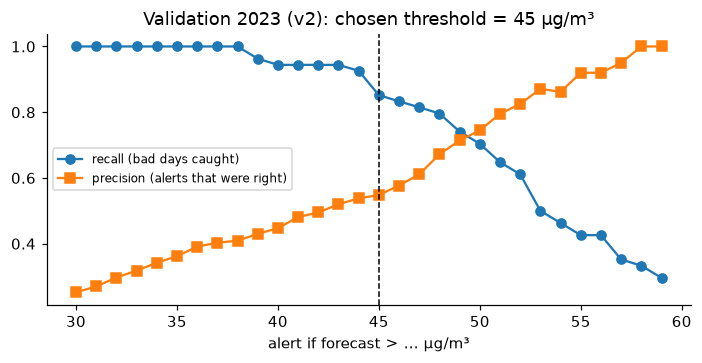

Thresholds chosen on validation (µg/m³): {'persistence': 27, 'weekday rule': 35, 'v1': 49, 'v2': 45}


In [6]:
def pick_threshold(actual, pred, min_recall=0.85):
    ok = [a for a in np.arange(20, 80, 1.0) if scores(actual, pred, alert_at=a)["recall"] >= min_recall]
    return float(max(ok))

val_preds = {"persistence": baseline_persistence(val),
             "weekday rule": baseline_weekday_rule(train0, val),
             "v1": AireManana().fit(train).predict(val),
             "v2": AireManana().fit(train).forecast(val)}
THRESHOLD = {k: pick_threshold(val.target, p) for k, p in val_preds.items()}
ALERT_AT = THRESHOLD["v2"]
grid = pd.DataFrame([{"alert_at": a, **scores(val.target, val_preds["v2"], alert_at=a)} for a in np.arange(30, 60, 1.0)])
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(grid.alert_at, grid.recall, "o-", label="recall (bad days caught)")
ax.plot(grid.alert_at, grid.precision, "s-", label="precision (alerts that were right)")
ax.axvline(ALERT_AT, color="k", ls="--", lw=1); ax.set_xlabel("alert if forecast > … µg/m³"); ax.legend(fontsize=8)
ax.set_title(f"Validation 2023 (v2): chosen threshold = {ALERT_AT:.0f} µg/m³"); fig.tight_layout()
fig.savefig("figures/threshold.png", dpi=150); plt.show()
print("Thresholds chosen on validation (µg/m³):", {k: int(v) for k, v in THRESHOLD.items()})

**What this shows.** The plot is v2 on the validation year. A higher threshold means fewer alerts: more of them are right
(precision goes up) but more bad days are missed (recall goes down). The rule picks the highest threshold that still catches 85 %
of bad days: **45 µg/m³** for v2. Every method gets its own threshold with the same rule. Persistence needs 27, because it cannot
see tomorrow's weather and has to alert early to catch the bad days — which costs it many false alarms in the test.

## 4. Final test — March 2024 to October 2026, with real day-ahead weather forecasts
Each method alerts when its forecast is above **its own threshold chosen on validation** (rule above).

*Honesty note:* the test period was scored twice — once for v1, and once more for v2 after the drift found in section 5.
Nothing else (features, training years, thresholds) was tuned on it. Both results are shown.

In [7]:
final = AireManana().fit(period(T_obs, "2020-07-01", "2024-02-28"))
train_all = period(T_obs, "2015-01-08", "2024-02-28")
T_test_obs = T_obs[T_obs.date.isin(test.date)]   # same days, but with the weather that really happened
methods = [
    ("Baseline: persistence (today so far)", test, baseline_persistence(test), THRESHOLD["persistence"]),
    ("Baseline: weekday rule", test, baseline_weekday_rule(train_all, test), THRESHOLD["weekday rule"]),
    ("AireMañana v1 (ECMWF forecast from the day before)", test, final.predict(test), THRESHOLD["v1"]),
    ("AireMañana v2 = v1 + 30-day error correction", test, final.forecast(test), THRESHOLD["v2"]),
    ("v2 with perfect weather (upper bound)", T_test_obs, final.forecast(T_test_obs), THRESHOLD["v2"]),
]
results = pd.DataFrame([{"method": n, "alert_at": a, **scores(T.target, p, alert_at=a)} for n, T, p, a in methods])
results.insert(4, "bias", [round(float(np.nanmean(p - T.target.to_numpy())), 1) for _, T, p, _ in methods])
results

,method,alert_at,days,mean_abs_error,bias,bad_days,caught,missed,false_alarms,recall,precision
0,Baseline: persistence (today so far),27.0,932,7.97,-2.1,45,38,7,223,0.844,0.146
1,Baseline: weekday rule,35.0,932,7.82,0.9,45,34,11,153,0.756,0.182
2,AireMañana v1 (ECMWF forecast from the day bef...,49.0,932,7.49,6.3,45,36,9,58,0.800,0.383
3,AireMañana v2 = v1 + 30-day error correction,45.0,932,4.44,-0.3,45,30,15,30,0.667,0.500
4,v2 with perfect weather (upper bound),45.0,932,4.16,-0.4,45,33,12,25,0.733,0.569


**What this shows, in plain words.**
* v2 misses tomorrow's mean by **4.4 µg/m³** on average; "tomorrow = today" misses by **8.0** — 44 % less error.
* Its bias is −0.3: no tendency to over- or under-forecast. v1 had +6.3.
* At its own threshold (45) v2 caught 30 of the 45 bad days with 30 false alarms. Persistence caught more (38), but only by
  alerting on 261 days, 223 of them for nothing: PE would move indoors on more than one day in four without reason, and a
  teacher stops trusting an alert like that.
* With perfect weather (last row: the weather that really happened) the error only drops to 4.16, so the weather forecast is
  not what limits the model.

### Fair comparison of the alert: bad days caught for the same number of false alarms
A threshold is just one setting. The curve shows, for every possible threshold, how many bad days each method would catch against
how many false alarms it would raise in the test period. It is **only for reporting** — nothing is chosen from it.

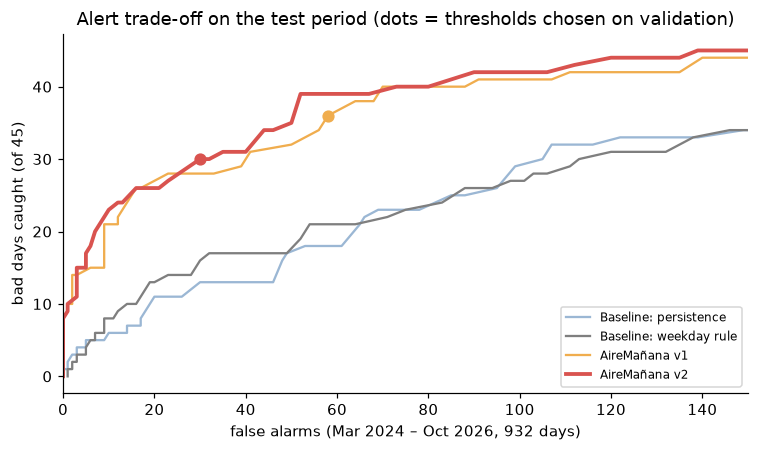

Error: 8.0 → 4.4 µg/m³ (44% lower than persistence)
With at most 30 false alarms: persistence catches 13/45 bad days, AireMañana v2 catches 30/45


,caught with ≤ 15 false alarms,caught with ≤ 30 false alarms,caught with ≤ 60 false alarms
Baseline: persistence,7,13,18
Baseline: weekday rule,10,16,21
AireMañana v1,25,28,36
AireMañana v2,24,30,39


In [8]:
bad = test.target.to_numpy() > LIMIT
cuts = np.arange(5, 95, 0.5)
fig, ax = plt.subplots(figsize=(7, 4.2))
budget = {}
for (name, T, p, a), color in zip(methods[:4], ["#9bb7d4", "#7f7f7f", "#f0ad4e", "#d9534f"]):
    fa = np.array([((~bad) & (p > x)).sum() for x in cuts]); ca = np.array([(bad & (p > x)).sum() for x in cuts])
    label = name.split(" (")[0].replace(" = v1 + 30-day error correction", "")
    ax.plot(fa, ca, color=color, lw=2.5 if "v2" in name else 1.5, label=label)
    ax.plot(((~bad) & (p > a)).sum(), (bad & (p > a)).sum(), "o", color=color, ms=7)
    budget[label] = {f"caught with ≤ {n} false alarms": int(ca[fa <= n].max()) for n in (15, 30, 60)}
ax.set_xlim(0, 150); ax.set_xlabel("false alarms (Mar 2024 – Oct 2026, 932 days)"); ax.set_ylabel(f"bad days caught (of {bad.sum()})")
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Alert trade-off on the test period (dots = thresholds chosen on validation)")
fig.tight_layout(); fig.savefig("figures/tradeoff.png", dpi=150); plt.show()
budget = pd.DataFrame(budget).T
b, m = results.iloc[0], results.iloc[3]
print(f"Error: {b.mean_abs_error:.1f} → {m.mean_abs_error:.1f} µg/m³ ({(1 - m.mean_abs_error / b.mean_abs_error) * 100:.0f}% lower than persistence)")
print(f"With at most 30 false alarms: persistence catches {budget.iloc[0, 1]}/{bad.sum()} bad days, AireMañana v2 catches {budget.iloc[3, 1]}/{bad.sum()}")
budget

**What this shows.** Each curve is one method with every possible threshold; higher and further left is better. For the same
budget of 30 false alarms in 32 months, v2 catches 30 bad days and persistence 13. The dots are the thresholds chosen on
validation.

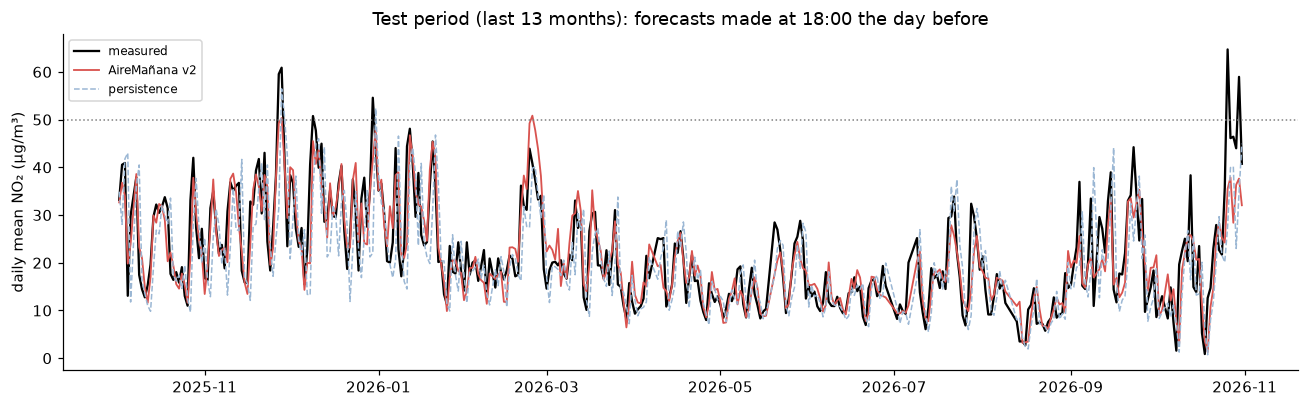

In [9]:
test = test.assign(pred=final.forecast(test), pred_v1=final.predict(test), persistence=baseline_persistence(test))
fig, ax = plt.subplots(figsize=(12, 3.8))
last = test[test.date >= "2025-10-01"]
ax.plot(last.tomorrow, last.target, color="k", lw=1.5, label="measured")
ax.plot(last.tomorrow, last.pred, color="#d9534f", lw=1.2, label="AireMañana v2")
ax.plot(last.tomorrow, last.persistence, color="#9bb7d4", lw=1, ls="--", label="persistence")
ax.axhline(LIMIT, color="gray", ls=":", lw=1); ax.set_ylabel("daily mean NO₂ (µg/m³)")
ax.set_title("Test period (last 13 months): forecasts made at 18:00 the day before"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/test_timeseries.png", dpi=150); plt.show()

**What this shows.** The last 13 months of the test. The red forecast follows the measured black line, including the drops at
weekends and holidays. The dashed persistence line is almost the measured line moved one day to the right: it always reacts a
day late, which is exactly what a teacher can't use.

## 5. Our question: does a model trained on the old Madrid still work?
We compare four versions on the test years. *Bias* = average (forecast − measured): positive means the model expects dirtier air
than there really is. A model stuck in the old Madrid should show a bias that **grows year after year**.
1. the blend trained on all years 2015 → Feb 2024, predicting the **absolute** level;
2. the same, predicting the **relative** change from today;
3. v1: relative, trained only from July 2020;
4. v2: v1 + the running 30-day error correction.

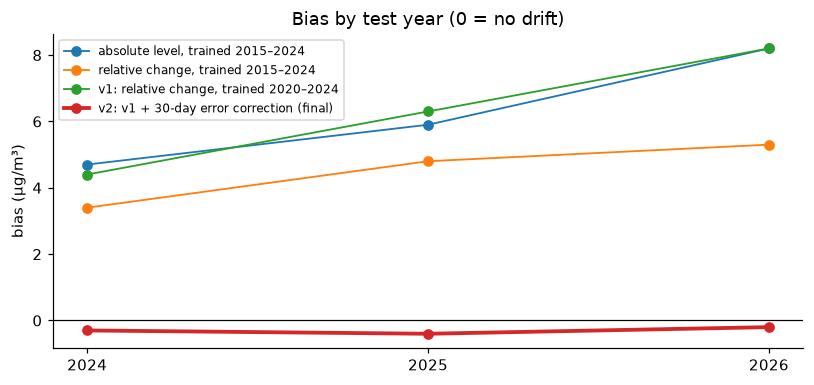

bias           mean_abs_error            
year                                     2024 2025 2026           2024  2025  2026
model                                                                             
absolute level, trained 2015–2024         4.7  5.9  8.2           6.69  7.11  8.74
relative change, trained 2015–2024        3.4  4.8  5.3           6.23  6.53  6.57
v1: relative change, trained 2020–2024    4.4  6.3  8.2           6.36  7.42  8.76
v2: v1 + 30-day error correction (final) -0.3 -0.4 -0.2           4.93  4.22  4.18

In [10]:
preds = {"absolute level, trained 2015–2024": AireManana(relative=False).fit(train_all).predict(test),
         "relative change, trained 2015–2024": AireManana().fit(train_all).predict(test),
         "v1: relative change, trained 2020–2024": final.predict(test),
         "v2: v1 + 30-day error correction (final)": final.forecast(test)}
rows = []
for name, p in preds.items():
    for year in [2024, 2025, 2026]:
        k = (test.tomorrow.dt.year == year).to_numpy()
        rows.append({"model": name, "year": year, "bias": round(float(np.mean(p[k] - test.target.to_numpy()[k])), 1),
                     **{x: scores(test.target.to_numpy()[k], p[k])[x] for x in ["mean_abs_error", "bad_days"]}})
drift = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for name, g in drift.groupby("model", sort=False): ax.plot(g.year, g.bias, "o-", label=name, lw=2.5 if name.startswith("v2") else 1.2)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks([2024, 2025, 2026]); ax.set_ylabel("bias (µg/m³)"); ax.legend(fontsize=8)
ax.set_title("Bias by test year (0 = no drift)"); fig.tight_layout()
fig.savefig("figures/drift.png", dpi=150); plt.show()
drift.pivot(index="model", columns="year", values=["bias", "mean_abs_error"]).loc[list(preds)]

**What this shows.** Look at the bias columns. The absolute model and v1 drift upwards year after year (v1: +4.4 → +6.3 → +8.2):
they keep expecting pollution that no longer comes. Predicting the *change* from today drifts less, because it starts from
today's real level, but it still drifts. v2 stays at −0.3, −0.4 and −0.2, and its error falls to about 4.2. One cheap idea —
checking your own recent errors — fixed what more years of data could not.

## 6. Where does it fail?
### 6a. The bad days it missed and its worst false alarms

In [11]:
real_w = weather_obs.rename(columns={"date": "tomorrow", "rain": "rain_real", "wind_mean": "wind_real"})[["tomorrow", "rain_real", "wind_real"]]
look = test.merge(real_w, on="tomorrow")
look["day"] = look.tomorrow.dt.day_name()
cols = ["tomorrow", "day", "target", "pred", "persistence", "rain_tomorrow", "rain_real", "wind_mean_tomorrow", "wind_real"]
missed = look[(look.target > LIMIT) & (look.pred <= ALERT_AT)].sort_values("target", ascending=False)
false_alarms = look[(look.target <= LIMIT) & (look.pred > ALERT_AT)].assign(err=lambda d: d.pred - d.target).sort_values("err", ascending=False)
print("MISSED bad days (forecast vs. real weather for that day):")
display(missed[cols].round(1).head(8))
print("Worst FALSE ALARMS:")
display(false_alarms[cols].round(1).head(5))

MISSED bad days (forecast vs. real weather for that day):


,tomorrow,day,target,pred,persistence,rain_tomorrow,rain_real,wind_mean_tomorrow,wind_real
926,2026-10-26,Monday,64.7,35.5,27.7,0.0,0.0,3.4,3.8
353,2025-02-27,Thursday,62.5,44.1,32.7,0.9,3.2,4.1,3.3
280,2024-12-14,Saturday,59.8,41.6,34.1,0.0,0.0,2.4,2.3
930,2026-10-30,Friday,59.0,37.6,34.6,0.0,0.0,3.2,3.6
272,2024-12-06,Friday,58.9,42.2,62.6,0.0,0.0,2.5,2.7
209,2024-09-30,Monday,57.7,33.3,13.7,0.0,0.0,6.1,5.0
262,2024-11-26,Tuesday,57.6,41.9,23.5,0.0,0.0,3.6,3.7
11,2024-03-12,Tuesday,55.5,39.3,18.9,0.0,0.0,3.8,4.6


Worst FALSE ALARMS:


,tomorrow,day,target,pred,persistence,rain_tomorrow,rain_real,wind_mean_tomorrow,wind_real
250,2024-11-12,Tuesday,24.0,46.7,31.1,0.0,0.0,9.1,12.7
44,2024-04-16,Tuesday,25.0,45.4,43.1,0.0,0.0,5.2,9.2
297,2024-12-31,Tuesday,41.4,56.0,34.8,0.0,0.0,3.8,4.8
277,2024-12-11,Wednesday,31.4,45.9,44.7,0.0,0.0,5.3,6.0
338,2025-02-11,Tuesday,35.7,47.1,49.0,3.0,1.9,4.5,5.4


**What this shows.** Most misses are dry days after a cleaner day: on 30 Sep 2024 today's level so far was 13.7 and the next day
measured 57.7; on 26 Oct 2026 it went from 27.7 to 64.7. The weather forecast was right on those days (no rain forecast, none
fell), so the miss comes from the model, which is cautious about sudden jumps. The worst false alarms were days that turned out
windier than forecast (12 Nov 2024: 9.1 km/h forecast, 12.7 km/h measured) — and wind blows NO₂ away.

In [12]:
by_month = look.assign(month=look.tomorrow.dt.month).groupby("month").apply(
    lambda g: pd.Series({"model_error": np.mean(np.abs(g.pred - g.target)), "persistence_error": np.mean(np.abs(g.persistence - g.target)),
                         "mean_no2": g.target.mean()})).round(1)
by_month.T

month,1,2,3,4,5,6,7,8,9,10,11,12
model_error,4.6,5.2,4.8,3.8,3.5,3.2,3.9,3.6,4.6,5.7,5.3,6.1
persistence_error,11.1,10.4,7.5,6.3,5.7,4.7,7.0,5.5,8.6,9.6,10.3,12.7
mean_no2,33.5,34.3,23.8,21.1,18.2,17.1,18.1,15.9,23.1,25.9,34.8,40.8


**What this shows.** Error by month of the year. It is largest from October to February (5–6 µg/m³), when NO₂ is highest and
cold, still air traps it; it is smallest in early summer (3.2 in June). v2 beats persistence in every month, and by the most in
winter (December: 6.1 against 12.7) — exactly when it matters.

### 6b. Who does it work for? All 24 stations of the city
The model was trained only on Escuelas Aguirre. We apply it, without re-training, to every other station in the test period.
v2's error correction is computed **separately for each station** from that station's own recent errors.

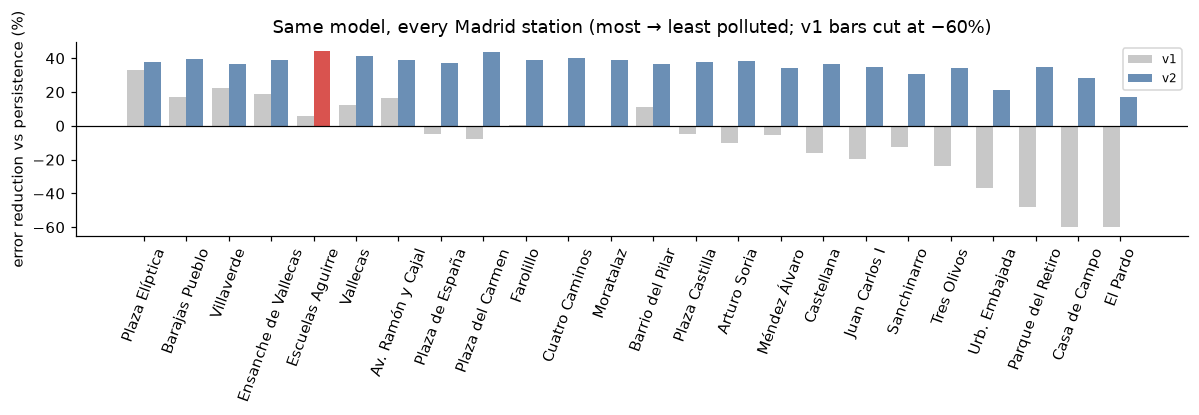

,station,mean_no2,days,persistence_error,v1_error,v2_error,v1_improvement_%,v2_improvement_%,bad_days,caught_v2,false_alarms_v2
19,Plaza Elíptica,31.0,952,9.42,6.33,5.89,32.8,37.5,85,64,66
7,Barajas Pueblo,27.6,953,9.55,7.95,5.78,16.8,39.5,49,32,38
4,Villaverde,26.5,957,9.96,7.74,6.30,22.3,36.7,82,52,32
17,Ensanche de Vallecas,24.8,961,9.89,8.00,6.04,19.1,38.9,50,23,18
1,Escuelas Aguirre,24.3,932,7.97,7.49,4.44,6.0,44.3,45,30,30
12,Vallecas,24.1,960,8.96,7.88,5.24,12.1,41.5,44,25,23
2,Av. Ramón y Cajal,23.9,956,9.67,8.06,5.89,16.6,39.1,41,16,25
0,Plaza de España,23.2,960,7.71,8.10,4.86,-5.1,37.0,20,13,16
8,Plaza del Carmen,23.0,940,7.64,8.21,4.30,-7.5,43.7,29,16,19
5,Farolillo,22.8,943,8.02,7.99,4.91,0.4,38.8,21,11,23


In [13]:
rows = []
for st in sorted(no2.station.unique()):
    Ts = build_table(no2, st, weather_obs, weather_fc).dropna(subset=["target", "no2_today_to_18h", "temp_mean_tomorrow"])
    Ts = Ts[Ts.date >= "2024-02-29"]
    if len(Ts) < 200: continue
    s_1, s_2 = scores(Ts.target, final.predict(Ts)), scores(Ts.target, final.forecast(Ts), alert_at=ALERT_AT)
    s_b = scores(Ts.target, baseline_persistence(Ts))
    rows.append({"station": STATIONS.get(st, st), "mean_no2": round(Ts.target.mean(), 1), "days": s_2["days"],
                 "persistence_error": s_b["mean_abs_error"], "v1_error": s_1["mean_abs_error"], "v2_error": s_2["mean_abs_error"],
                 "v1_improvement_%": round(100 * (1 - s_1["mean_abs_error"] / s_b["mean_abs_error"]), 1),
                 "v2_improvement_%": round(100 * (1 - s_2["mean_abs_error"] / s_b["mean_abs_error"]), 1),
                 "bad_days": s_2["bad_days"], "caught_v2": s_2["caught"], "false_alarms_v2": s_2["false_alarms"]})
stations = pd.DataFrame(rows).sort_values("mean_no2", ascending=False)
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(stations))
ax.bar(x - 0.2, stations["v1_improvement_%"].clip(lower=-60), 0.4, color="#c8c8c8", label="v1")
ax.bar(x + 0.2, stations["v2_improvement_%"], 0.4, color=["#d9534f" if s == STATIONS[STATION] else "#6b8fb5" for s in stations.station], label="v2")
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x, stations.station, rotation=70)
ax.set_ylabel("error reduction vs persistence (%)"); ax.legend(fontsize=8)
ax.set_title("Same model, every Madrid station (most → least polluted; v1 bars cut at −60%)"); fig.tight_layout()
fig.savefig("figures/stations.png", dpi=150); plt.show()
stations

**What this shows.** The model learned only from Escuelas Aguirre, yet v2 beats persistence at **all 24 stations** (17–44 % less
error). v1 was *worse* than persistence at 14 of them — the cleaner ones (El Pardo, Casa de Campo, Retiro…), where expecting
"old Madrid" pollution hurts most. Because v2 corrects each station with that station's own recent errors, it adapts to every
place without re-training. This is what lets the website cover the whole city.

## 7. Demo — the real forecast for tomorrow
Live data: NO₂ up to yesterday from the European Environment Agency (E2a up-to-date data), today's hours from Madrid's
real-time file, and the newest ECMWF forecast. Run this cell at 18:00 to get the alert exactly as the teacher would.

AireMañana · Escuelas Aguirre · forecast made 14 Nov 2026 for Sunday 15 Nov
Tomorrow's mean NO2: 7 µg/m³ (EU 2030 daily limit: 50) -> OK: outdoor activity is fine tomorrow
Today so far: 8 µg/m³ (12 hours measured)
Weather tomorrow (ECMWF): rain 2.1 mm, wind 15 km/h, 0 calm hours, 9-12 °C
Why (effect on tomorrow vs. today, compared with a typical day): NO2 of the last days +58%, Learning from last 30 days' errors -31%, Temperature & pressure -22%, Day of the week / holiday -19%, Season +17%, Wind -9%, Rain -6%


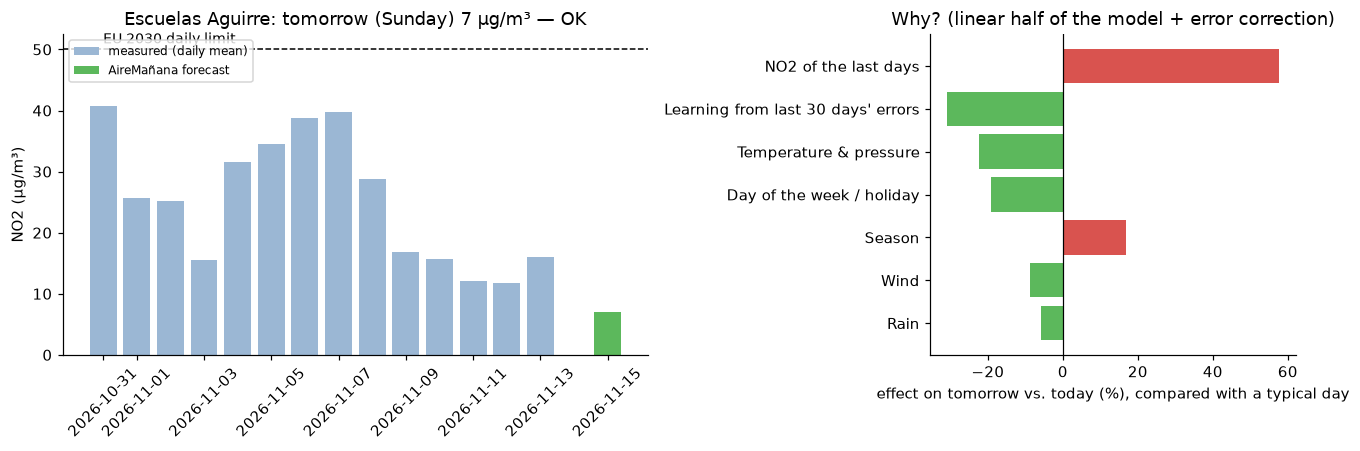

In [14]:
from live import forecast_tomorrow, show
f = forecast_tomorrow(final, STATION, alert_at=ALERT_AT)
show(f, save="figures/live_forecast.png")

**What this shows.** The forecast exactly as a teacher would get it, with its reasons. Each *why* percentage says how much one
group of inputs pushes tomorrow up (+) or down (−) compared with a typical day. The output above is from the day the notebook was
last run; run the cell again to get today's.

## 8. From one station to every school
A teacher doesn't know which air-quality station is theirs. So we took the City of Madrid's official list of education centres
(open data, CC BY 4.0): public and state-funded schools, secondary schools, nursery schools and special-education centres —
**1,253** with coordinates — and linked each one to its **nearest station** (straight-line distance with the haversine formula).
On the website a teacher types the school's name and gets that station's forecast, with the distance next to it; every school
also gets its own link (`?sc=<id>`) and a printable poster.

The table is built once with `python make_site_data.py schools` and saved in `web/data/schools.json`.

1,253 schools · Ayuntamiento de Madrid, Centros educativos (datos.madrid.es, CC BY 4.0) · downloaded 2026-11-14
Distance to the nearest station: median 1.3 km · 34% within 1 km · 76% within 2 km · 91% within 3 km · farthest 6.9 km (Colegio Japonés de Madrid, Moncloa-Aravaca)
Example: [{'name': 'CEIP Cervantes', 'station_name': 'Cuatro Caminos', 'km': 0.36}]


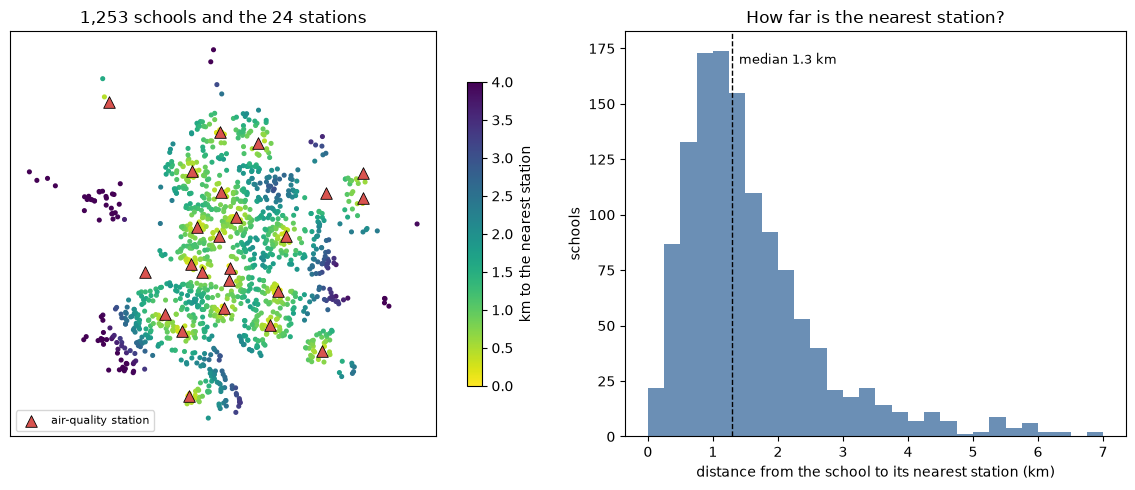

,schools,median km to station
type,,
Private and state-funded schools,312,1.2
Private nursery schools,430,1.3
Private special-education centres,28,1.4
Public nursery schools,156,1.4
Public schools (CEIP),249,1.3
Public secondary schools (IES),67,1.4
Public special-education centres,11,1.8


In [201]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt

S = json.load(open("web/data/schools.json"))
schools = pd.DataFrame(S["schools"], columns=S["fields"])
TYPE = {"ColegiosPublicos": "Public schools (CEIP)", "ColegiosPrivadosConcertados": "Private and state-funded schools",
        "InstitutosEnseñanzaSecundaria": "Public secondary schools (IES)", "EscuelasInfantilesPublicas": "Public nursery schools",
        "EscuelasInfantilesPrivadasGuarderias": "Private nursery schools",
        "CentrosPublicosEducacionEspecial": "Public special-education centres",
        "CentrosPrivadosConcertadosEducacionEspecial": "Private special-education centres"}
schools["type"] = schools["type"].map(lambda i: TYPE[S["types"][i]])
stations = pd.DataFrame(json.load(open("web/data/forecast.json"))["stations"])[["id", "name", "lat", "lon"]]
schools["station_name"] = schools.station.map(stations.set_index("id").name)

far = schools.loc[schools.km.idxmax()]
print(f"{len(schools):,} schools · {S['source']} · downloaded {S['downloaded']}")
print(f"Distance to the nearest station: median {schools.km.median():.1f} km · "
      + " · ".join(f"{(schools.km <= k).mean():.0%} within {k} km" for k in (1, 2, 3))
      + f" · farthest {far.km:.1f} km ({far['name']}, {far.district})")
print("Example:", schools[schools.name == "CEIP Cervantes"][["name", "station_name", "km"]].to_dict("records"))

fig, ax = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.2, 1]})
sc = ax[0].scatter(schools.lon, schools.lat, c=schools.km, s=7, cmap="viridis_r", vmin=0, vmax=4)
ax[0].scatter(stations.lon, stations.lat, marker="^", s=70, color="#d9534f", edgecolor="k", lw=0.6, label="air-quality station")
ax[0].set_aspect(1 / np.cos(np.radians(40.42))); ax[0].set_xticks([]); ax[0].set_yticks([])
ax[0].legend(loc="lower left", fontsize=8); fig.colorbar(sc, ax=ax[0], shrink=0.75, label="km to the nearest station")
ax[0].set_title(f"{len(schools):,} schools and the {len(stations)} stations")
ax[1].hist(schools.km, bins=np.arange(0, 7.25, 0.25), color="#6b8fb5")
ax[1].axvline(schools.km.median(), color="k", ls="--", lw=1)
ax[1].text(schools.km.median() + 0.1, ax[1].get_ylim()[1] * 0.92, f"median {schools.km.median():.1f} km", fontsize=9)
ax[1].set_xlabel("distance from the school to its nearest station (km)"); ax[1].set_ylabel("schools")
ax[1].set_title("How far is the nearest station?")
fig.tight_layout(); fig.savefig("figures/schools.png", dpi=150); plt.show()

pd.DataFrame({"schools": schools.type.value_counts(),
              "median km to station": schools.groupby("type").km.median().round(1)})

**What this shows.** Half of the schools are within 1.3 km of a station, three in four within 2 km and nine in ten within
3 km. The farthest ones are at the edges of the city, where stations are fewer. Nursery schools are the largest group (586 of
1,253), so the forecast also reaches the youngest children. *Honest limit:* the nearest station is not the school's own air —
that's why the website always shows the distance.

## 9. When is the air cleanest during the school day?
The daily mean decides *whether* PE goes outdoors. But inside a day NO₂ follows the traffic, so the website also suggests the
**best two hours for PE tomorrow**, between 9:00 and 17:00.

**How.** For each station we learned the typical *shape* of a day from the same years as the model (July 2020 – February 2024):
each hour's NO₂ divided by that day's mean, averaged separately for school days, Saturdays and Sundays/holidays, and for the cold
(October–March) and warm (April–September) half of the year. The suggested window is the two-hour slot with the lowest shape.
Multiplying the shape by tomorrow's forecast gives the curve drawn on the website.

*Honest note:* this is a **typical day**, not an hourly forecast — a traffic jam or a change in the wind can move tomorrow's real
hours. That's why it is checked below on the test years, which were never used to learn the shapes. Built with
`python make_site_data.py profiles`, saved in `web/data/profiles.json`.

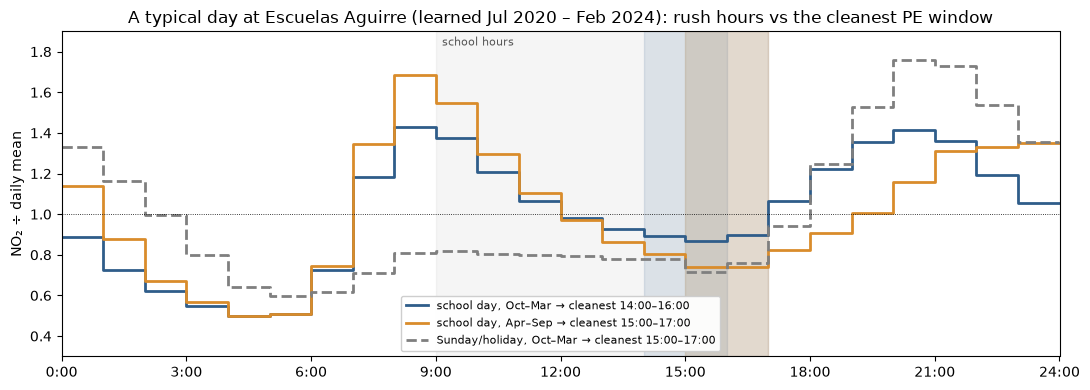

Cleanest window on a school day, Oct–Mar: 14:00–16:00 at 16 stations, 15:00–17:00 at 4 stations, 13:00–15:00 at 3 stations, 12:00–14:00 at 1 station
Cleanest window on a school day, Apr–Sep: 15:00–17:00 at 23 stations, 14:00–16:00 at 1 station

Check on the test period: 13,485 school days × stations, 2024-02-29 – 2026-10-30
The suggested window was the cleanest of the 7 on 50 % of days, one of the two cleanest on 72 %, and cleaner than the school-day average on 90 %.


,mean NO₂ on test days (µg/m³)
suggested 2-hour window,14.8
whole school day (9:00–17:00),21.1
first lesson (9:00–11:00),30.4
"cleanest window, known only afterwards",12.9
dirtiest window,32.1


In [202]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter

P = json.load(open("web/data/profiles.json"))
names = {str(s["id"]): s["name"] for s in json.load(open("web/data/forecast.json"))["stations"]}
W = P["windows"]                                         # a 2-hour window can start at 9:00 … 15:00
best = lambda shape: min(W, key=lambda a: shape[a] + shape[a + 1])
DAY, SEASON = {"0": "school day", "1": "Saturday", "2": "Sunday/holiday"}, {"0": "Oct–Mar", "1": "Apr–Sep"}

st = "8"                                                 # Escuelas Aguirre
fig, ax = plt.subplots(figsize=(11, 4))
ax.axvspan(9, 17, color="#000", alpha=0.04); ax.text(9.15, 1.83, "school hours", fontsize=8, color="#555")
for key, color, ls in [("00", "#2f5d8a", "-"), ("01", "#d98c2b", "-"), ("20", "#7f7f7f", "--")]:
    shape, a = P["shape"][st][key], best(P["shape"][st][key])
    ax.step(range(25), shape + shape[-1:], where="post", color=color, ls=ls, lw=2,
            label=f"{DAY[key[0]]}, {SEASON[key[1]]} → cleanest {a}:00–{a + 2}:00")
    ax.axvspan(a, a + 2, color=color, alpha=0.13)
ax.axhline(1, color="k", lw=0.6, ls=":")
ax.set_xlim(0, 24); ax.set_ylim(0.3, 1.9); ax.set_xticks(range(0, 25, 3)); ax.set_xticklabels([f"{h}:00" for h in range(0, 25, 3)])
ax.set_ylabel("NO₂ ÷ daily mean"); ax.legend(fontsize=8, loc="lower center", framealpha=0.95)
ax.set_title(f"A typical day at {names[st]} (learned Jul 2020 – Feb 2024): rush hours vs the cleanest PE window")
fig.tight_layout(); fig.savefig("figures/best_hour.png", dpi=150); plt.show()

for key in ["00", "01"]:
    n = Counter(best(P["shape"][s][key]) for s in P["shape"] if key in P["shape"][s])
    print(f"Cleanest window on a {DAY[key[0]]}, {SEASON[key[1]]}: " +
          ", ".join(f"{a}:00–{a + 2}:00 at {k} station{'s' if k > 1 else ''}" for a, k in n.most_common()))

c = P["check"]
print(f"\nCheck on the test period: {c['station_days']:,} school days × stations, {c['from']} – {c['to']}")
print(f"The suggested window was the cleanest of the 7 on {c['was_cleanest_pct']:.0f} % of days, one of the two cleanest on "
      f"{c['top2_pct']:.0f} %, and cleaner than the school-day average on {c['cleaner_than_school_day_pct']:.0f} %.")
pd.Series({"suggested 2-hour window": c["picked"], "whole school day (9:00–17:00)": c["school_day"],
           "first lesson (9:00–11:00)": c["morning"], "cleanest window, known only afterwards": c["best_possible"],
           "dirtiest window": c["worst"]}, name="mean NO₂ on test days (µg/m³)").to_frame()

**What this shows.** NO₂ follows the traffic: high in the morning rush (the peak is around 8:00–9:00, when children arrive),
lower after lunch, and up again in the evening. On a school day the cleanest window is 14:00–16:00 at most stations in the cold
half of the year, and 15:00–17:00 at almost every station in the warm half. On the test years the suggested window averaged
14.8 µg/m³ — **30 % less** than the school-day average (21.1) and **51 % less** than the first lesson at 9:00–11:00 (30.4).
It was the single cleanest window on half of the days and cleaner than the school-day average on 9 days in 10. A simple,
checkable tip a teacher can use even on a "green" day.

## 10. The website, and a test that grows every evening
Everything above becomes a website that updates itself. Every evening at about 18:35 (Madrid winter time) a GitHub Action runs
`python make_site_data.py live`:
1. downloads today's hourly NO₂ (Madrid's real-time file), the last days (EEA) and the newest ECMWF weather forecast;
2. forecasts tomorrow for all 24 stations → `web/data/forecast.json`;
3. **saves every forecast before the day happens** in `web/data/log.csv`, next to what "tomorrow = today" would have said, and
   once a day has been measured, writes the real value next to it;
4. rewrites 48 calendar files, one per station and language (`web/cal/<station>-<en|es>.ics`);
5. publishes the website on GitHub Pages.

What a teacher can do on the site:

| Feature | What it does |
|---|---|
| Station picker and map | tomorrow's level, likely range, chance above 50 and the decision, for any of the 24 stations |
| Find your school | search 1,253 schools; shows the nearest station and how far it is (section 8) |
| Best time for PE | the cleanest two hours of tomorrow's school day (section 9) |
| Why this forecast? | how much each group of inputs pushes tomorrow up or down, as in the demo |
| Calendar | subscribe once in Apple, Google or Outlook Calendar; tomorrow's decision appears there every evening |
| Share | a ready-made image with tomorrow's forecast for WhatsApp or Instagram |
| Poster | a printable A4 sheet with a QR code to the school's forecast, for the staff room |
| Installable app | add it to the phone's home screen; it opens offline with the last forecast |
| Live record | every published forecast against what was measured |

The **live record** is the cleanest test of all: forecasts are saved before their day happens, so nothing can be tuned
afterwards. The cell below reads it (on Colab, the cloned repository always has the newest version).

In [203]:
import json
import pandas as pd

log = pd.read_csv("web/data/log.csv")
names = {s["id"]: s["name"] for s in json.load(open("web/data/forecast.json"))["stations"]}
done = log.dropna(subset=["measured"])
print(f"Published: {len(log):,} forecasts on {log.issued.nunique()} evening(s), the first on {log.issued.min()} · checked: {len(done):,}")
if len(done):
    line = f"AireMañana error {(done.forecast - done.measured).abs().mean():.1f} µg/m³ on {len(done):,} forecasts"
    if "persistence" in done and done.persistence.notna().any():
        d2 = done.dropna(subset=["persistence"])
        line += (f" · where 'tomorrow = today' was saved too ({len(d2):,}): AireMañana {(d2.forecast - d2.measured).abs().mean():.1f}"
                 f" vs persistence {(d2.persistence - d2.measured).abs().mean():.1f}")
    print(line)
else:
    print("No day checked yet: a forecast is checked the evening after the day it was made for.")

# the newest event of the Escuelas Aguirre calendar, as a calendar app receives it
ics = open("web/cal/8-en.ics", encoding="utf-8").read().replace("\n ", "")      # undo the 75-character line folding
event = ics.split("BEGIN:VEVENT")[-1]
field = lambda k: next(l.split(":", 1)[1] for l in event.splitlines() if l.startswith(k))
print("\nCalendar ·", field("DTSTART"), "·", field("SUMMARY"))
print("  " + field("DESCRIPTION").replace("\\n", "\n  ").replace("\\,", ",").replace("\\;", ";"))

latest = log[log.issued == log.issued.max()].assign(station=lambda d: d.station.map(names))
latest[["station", "for_day", "forecast", "low", "high", "p_exceed", "alert", "measured"]].sort_values("forecast", ascending=False).head(8)

Published: 23 forecasts on 1 evening(s), the first on 2026-11-14 · checked: 0
No day checked yet: a forecast is checked the evening after the day it was made for.

Calendar · 20261115 · 🟢 Outdoor PE OK · 8 µg/m³
  Outdoor PE and recess are fine.
  Likely range: 5–12 µg/m³
  Chance above the EU limit (50 µg/m³): <1 %
  Cleanest daytime hours (no school tomorrow): 15:00–17:00 (typical shape of the day)
  https://julianjms-beep.github.io/aire-manana/?st=8&lang=en
  Prototype, not medical advice.


,station,for_day,forecast,low,high,p_exceed,alert,measured
1,Plaza Elíptica,2026-11-15,21.0,14.3,30.0,0.005,False,NaN
12,Barrio del Pilar,2026-11-15,13.4,9.0,19.3,0.000,False,NaN
6,Villaverde,2026-11-15,12.1,8.1,17.5,0.000,False,NaN
13,Vallecas,2026-11-15,10.4,6.9,15.1,0.000,False,NaN
17,Plaza Castilla,2026-11-15,9.0,6.0,13.1,0.000,False,NaN
10,Moratalaz,2026-11-15,8.8,5.8,12.8,0.000,False,NaN
3,Plaza de España,2026-11-15,8.7,5.8,12.7,0.000,False,NaN
5,Arturo Soria,2026-11-15,8.7,5.7,12.6,0.000,False,NaN


**What this shows.** The record began on the evening of 14 November 2026. Every evening adds 24 forecasts, and the evening after
their day the measured value is written next to them, so AireMañana can be compared with "tomorrow = today" on days that did
not exist when the model was built. The calendar event is what a teacher subscribed to the station sees in their phone's
calendar. The website's *Live record* section shows the same numbers, updated every evening.

## 11. Limitations and next steps
* One pollutant: the alert is about NO₂ only (not ozone or PM2.5).
* The weather features describe central Madrid; stations at the edges of the city may need their own weather.
* The test covers March 2024 – October 2026, when bad days became rare (about 5 % of days), so the precision of the alert
  rests on few events.
* The test period was scored twice (v1, then v2 after we found the drift). The v2 fix was designed on validation data only,
  but a brand-new period is the cleanest check — the live record (section 10) collects one such test every evening.
* The 30-day correction needs a month of recent measurements; after a long data gap it starts from zero again.
* A school gets the forecast of its **nearest** station (median 1.3 km away). A playground next to a busy road can be dirtier
  than its station; one in a park can be cleaner.
* The best time for PE comes from a **typical day** for that station, season and type of day — not from an hourly forecast.
* The live record is still short; it needs a winter to say much about bad days, which mostly happen from October to February.
* **Next:** a pilot with a real school, with push alerts on top of the calendar; ozone in summer; local weather per station;
  training on all 24 stations at once.

## Sources
* Madrid City Council open data — air quality hourly data (2001–) and real-time data: https://datos.madrid.es
* Madrid City Council open data — education centres (*Centros educativos*), CC BY 4.0: https://datos.madrid.es
* European Environment Agency — up-to-date air quality data (E2a): https://eeadmz1-downloads-webapp.azurewebsites.net/
* Open-Meteo — ERA5 historical weather, Previous Runs API (archived ECMWF IFS forecasts) and Forecast API: https://open-meteo.com
* EU 2030 NO₂ daily limit (50 µg/m³, max 18 days/year), Directive (EU) 2024/2881, as summarised by the EEA:
  https://www.eea.europa.eu/en/analysis/publications/air-quality-status-report-2025/benchmark-analysis-against-the-standards-in-the-revised-directive-eu-2024-2881
* Libraries: pandas, NumPy, scikit-learn, matplotlib, holidays. Website: D3, MapLibre, OpenFreeMap tiles.
* AI tools: Claude Code (Anthropic, model Claude Opus 5.5) helped write and debug the code and the write-up;
  Higgsfield was used to produce the explanation video.